# 04 · Comparación por escenario y conclusiones

Los modelos estadísticos (serie diaria) y los de machine learning (serie horaria) responden preguntas distintas si se les da información distinta. Por eso la comparación se hace en tres escenarios, todos sobre los mismos 30 días de prueba (2012-12-02 a 2012-12-31) y cada uno con su tabla:

| Escenario | Pregunta | Modelos |
| --- | --- | --- |
| A. Hora siguiente | Con la demanda real hasta la hora h − 1, ¿cuántos alquileres en la hora h? | ML horario con todos los rezagos |
| B. Día siguiente | Al cierre de cada día, ¿cuántos alquileres mañana? | ARIMA, SARIMA y SARIMAX actualizados día a día; ML que predice las 24 horas de mañana con la información al cierre de hoy y las suma |
| C. Mes completo | El 1 de diciembre, ¿cuántos alquileres cada día de los 30 siguientes? | ARIMA, SARIMA y SARIMAX a 30 pasos; ML recursivo que usa sus propias predicciones como rezagos |

Todos los escenarios incluyen dos referencias ingenuas: **persistencia** (repetir el valor anterior disponible) y **estacional** (repetir la misma hora de ayer en A, o el mismo día de la semana anterior en B y C). Un modelo que no las supera no aporta. En todos se supone conocido el clima de los días a pronosticar, un supuesto optimista e igual para todos.

Métricas: MAE, RMSE, MAPE y WAPE (error absoluto total entre demanda total). El MAPE se dispara en los días de muy baja demanda de fin de año (el 26 de diciembre hubo 441 alquileres), así que la lectura principal se hace con el WAPE.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bike_sharing import RANDOM_STATE, datos
from bike_sharing.datos import RAIZ, INICIO_PRUEBA, FIN_PRUEBA

RESULTADOS = RAIZ / "results"
FIGURAS = RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 4.5), "figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
np.random.seed(RANDOM_STATE)

from bike_sharing.escenarios import PERSISTENCIA, ESTACIONAL

leer = lambda n: json.loads((RESULTADOS / n).read_text(encoding="utf-8"))
r_a, r_b, r_c = leer("escenario_a.json"), leer("escenario_b.json"), leer("escenario_c.json")
grupos = leer("por_grupo.json")
csv = lambda n: pd.read_csv(RESULTADOS / n, index_col=0, parse_dates=True)
pa, pb_h, pb_d, pc_h, pc_d = (csv(f"predicciones_{n}.csv") for n in ("a_horaria", "b_horaria", "b_diaria", "c_horaria", "c_diaria"))

INGENUOS = [PERSISTENCIA, ESTACIONAL]
ESTADISTICOS = [c for c in pb_d.columns if c.startswith(("ARIMA", "SARIMA"))]
ML = [c for c in pa.columns if c not in ["real", *INGENUOS]]

def tabla(metricas):
    t = pd.DataFrame(metricas).T[["MAE", "RMSE", "MAPE", "WAPE"]]
    t.columns = ["MAE", "RMSE", "MAPE (%)", "WAPE (%)"]
    return t

def familia(m):
    return "referencia" if m in INGENUOS else "estadístico" if m in ESTADISTICOS else "machine learning"

## Escenario A · hora siguiente (error por hora)

In [2]:
t = tabla(r_a["metricas"]); t.insert(0, "tipo", [familia(m) for m in t.index]); t

,tipo,MAE,RMSE,MAPE (%),WAPE (%)
XGBoost ajustado,machine learning,18.96,29.33,27.04,11.52
Random Forest,machine learning,20.49,32.44,26.90,12.45
XGBoost,machine learning,21.77,33.04,42.93,13.23
SVR,machine learning,24.29,36.65,51.74,14.76
Ridge,machine learning,40.19,60.33,67.25,24.42
Ingenuo: estacional,referencia,57.65,98.22,86.59,35.02
Ingenuo: persistencia,referencia,58.97,98.61,54.05,35.82


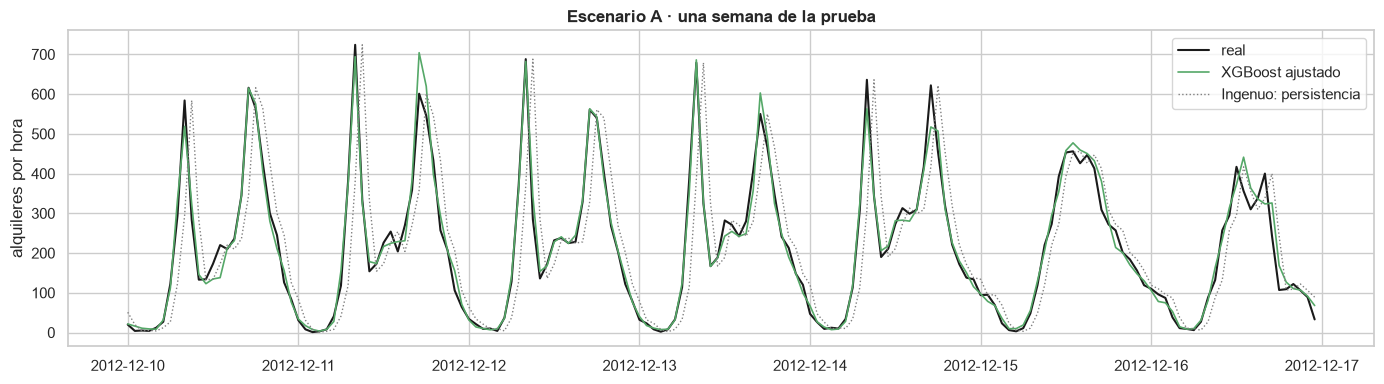

In [3]:
semana = slice("2012-12-10", "2012-12-16")
mejor_a = tabla(r_a["metricas"]).index[0]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(pa.loc[semana, "real"], "k-", lw=1.5, label="real")
ax.plot(pa.loc[semana, mejor_a], color="C2", lw=1.2, label=mejor_a)
ax.plot(pa.loc[semana, PERSISTENCIA], color="gray", lw=1, ls=":", label=PERSISTENCIA)
ax.set(title="Escenario A · una semana de la prueba", ylabel="alquileres por hora"); ax.legend()
plt.tight_layout(); plt.show()

Con la demanda de la hora anterior, XGBoost ajustado comete un error medio de unos 19 alquileres por hora (WAPE 11,5 %), un tercio del de las referencias ingenuas (35–36 %). Es el mismo orden que en la validación cruzada (notebook 03): XGBoost ajustado, Random Forest, XGBoost, SVR y, lejos, Ridge.

## Escenario B · día siguiente (error por día)

In [4]:
t = tabla(r_b["diario"]); t.insert(0, "tipo", [familia(m) for m in t.index]); t

,tipo,MAE,RMSE,MAPE (%),WAPE (%)
SVR,machine learning,470.76,580.94,17.11,11.92
XGBoost,machine learning,565.15,685.62,28.58,14.30
XGBoost ajustado,machine learning,591.91,713.86,31.28,14.98
Random Forest,machine learning,595.62,752.77,31.54,15.08
SARIMAX completo,estadístico,667.01,898.97,31.45,16.88
SARIMAX solo clima,estadístico,678.58,910.80,32.83,17.18
Ridge,machine learning,790.60,"1,087.57",52.68,20.01
SARIMAX solo calendario,estadístico,803.74,"1,053.43",50.22,20.34
Ingenuo: persistencia,referencia,818.07,"1,023.95",32.58,20.71
"ARIMA(1, 1, 1)",estadístico,874.42,"1,181.94",55.37,22.13


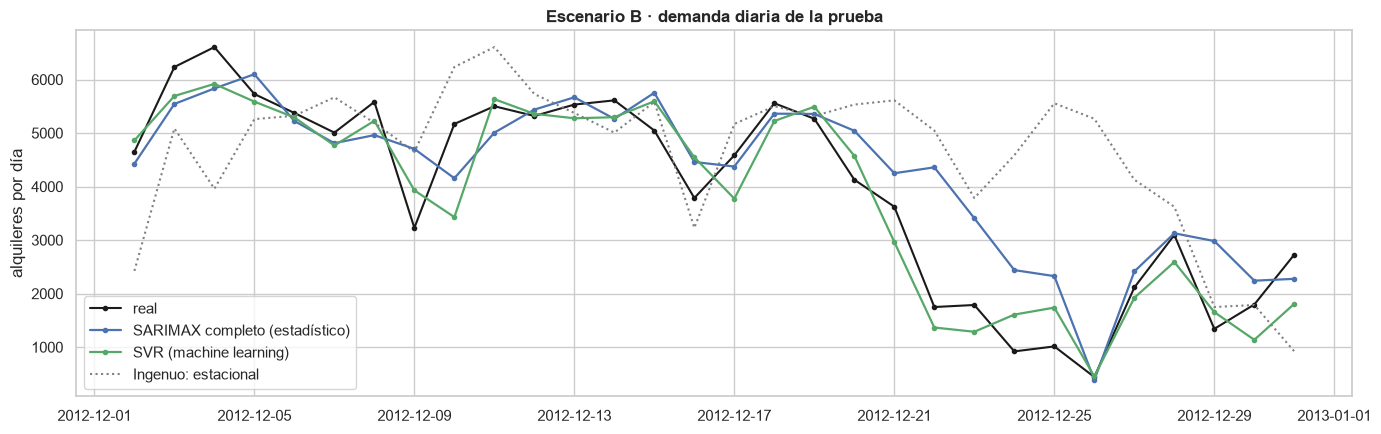

In [5]:
p = pc_d if "B" == "C" else pb_d
mejores = {f: tabla(r_b["diario"]).loc[lambda t: [familia(m) == f for m in t.index]].index[0]
           for f in ("estadístico", "machine learning")}
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(p["real"], "k.-", lw=1.5, label="real")
for (f, m), color in zip(mejores.items(), ("C0", "C2")):
    ax.plot(p[m], color=color, lw=1.6, marker="o", ms=3, label=f"{m} ({f})")
ax.plot(p[ESTACIONAL], color="gray", ls=":", label=ESTACIONAL)
ax.set(title="Escenario B · demanda diaria de la prueba", ylabel="alquileres por día"); ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(FIGURAS / "escenario_b.png", dpi=120, bbox_inches="tight"); plt.show()

- Todos los modelos de ML y los SARIMAX con clima superan a las dos referencias.
- **ARIMA y SARIMA sin exógenas no superan a la persistencia** (repetir el total de ayer): su WAPE es del 22–24 %, frente al 20,7 % de la persistencia. Para el día siguiente, la dinámica de la serie sola no aporta más que el último valor; lo que aporta es el clima.
- El SVR tiene el menor error (11,9 %), seguido de los modelos de árboles (14–15 %) y del SARIMAX completo (16,9 %).

El error de los modelos de ML medido hora por hora, en este mismo escenario:

In [6]:
tabla(r_b["horario"])

,MAE,RMSE,MAPE (%),WAPE (%)
SVR,31.97,48.36,57.20,19.42
XGBoost ajustado,35.82,55.14,67.91,21.76
XGBoost,37.83,59.52,66.43,22.98
Random Forest,40.66,66.38,62.27,24.70
Ridge,47.25,73.26,105.80,28.70
Ingenuo: persistencia,57.65,98.22,86.59,35.02
Ingenuo: estacional,63.27,109.60,130.73,38.43


## Escenario C · mes completo (error por día)

In [7]:
t = tabla(r_c["diario"]); t.insert(0, "tipo", [familia(m) for m in t.index]); t

,tipo,MAE,RMSE,MAPE (%),WAPE (%)
SVR,machine learning,407.05,503.65,18.09,10.30
XGBoost ajustado,machine learning,730.45,884.26,36.54,18.49
Ridge,machine learning,981.11,"1,164.43",44.00,24.83
XGBoost,machine learning,998.60,"1,350.89",61.95,25.28
Random Forest,machine learning,"1,103.90","1,251.76",57.94,27.94
SARIMAX completo,estadístico,"1,197.87","1,556.82",73.58,30.32
SARIMAX solo calendario,estadístico,"1,203.07","1,503.98",78.15,30.45
SARIMAX solo clima,estadístico,"1,206.25","1,568.94",74.16,30.53
SARIMA,estadístico,"1,432.26","1,814.94",95.13,36.25
"ARIMA(2, 1, 2) auto",estadístico,"1,518.91","1,847.11",96.38,38.45


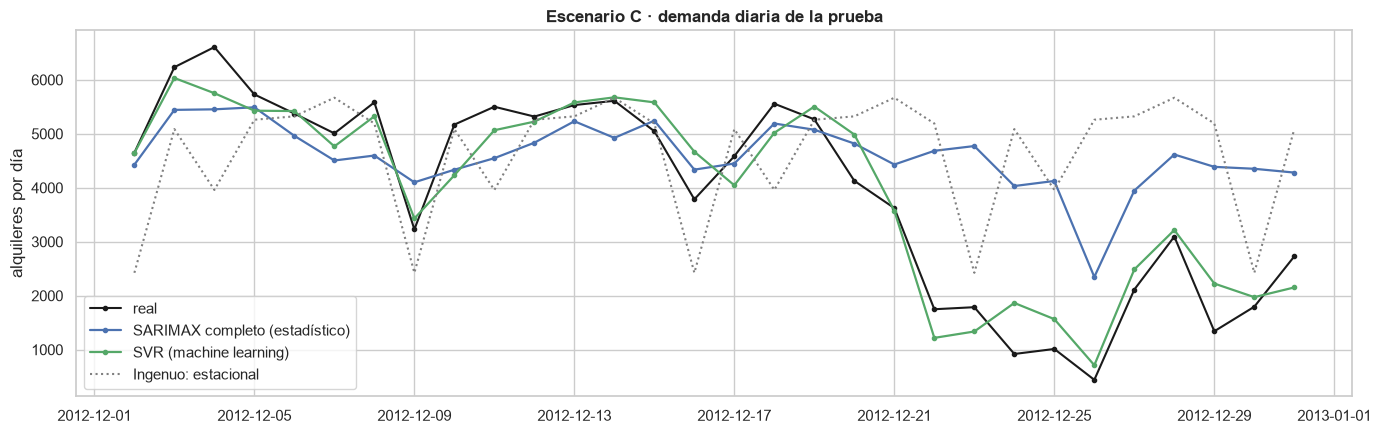

In [8]:
p = pc_d if "C" == "C" else pb_d
mejores = {f: tabla(r_c["diario"]).loc[lambda t: [familia(m) == f for m in t.index]].index[0]
           for f in ("estadístico", "machine learning")}
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(p["real"], "k.-", lw=1.5, label="real")
for (f, m), color in zip(mejores.items(), ("C0", "C2")):
    ax.plot(p[m], color=color, lw=1.6, marker="o", ms=3, label=f"{m} ({f})")
ax.plot(p[ESTACIONAL], color="gray", ls=":", label=ESTACIONAL)
ax.set(title="Escenario C · demanda diaria de la prueba", ylabel="alquileres por día"); ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(FIGURAS / "escenario_c.png", dpi=120, bbox_inches="tight"); plt.show()

- A 30 días, los SARIMAX quedan en torno al 30 % de WAPE y el SARIMA en 36 %, apenas por debajo de las referencias (38,7–40,2 %). El ARIMA(1, 1, 1) no supera a la referencia estacional.
- Los modelos de ML recursivos se degradan de forma desigual: el error se acumula porque cada predicción alimenta a la siguiente. El SVR (10,3 %) y XGBoost ajustado (18,5 %) se mantienen; XGBoost base y Random Forest pasan al 25–28 %.
- El SVR incluso tiene menos error diario a un mes que a un día. No es que sepa más: en C se usa el modelo del escenario A, entrenado con otras variables que el de B, y en el total diario los errores horarios de signo opuesto se compensan (por hora, su error sí crece: 19,4 % en B frente a 23,6 % en C).
- Ningún modelo estadístico anticipa la caída de las fiestas: su pronóstico sigue el nivel de comienzos de diciembre.

Error horario de los modelos de ML en este escenario:

In [9]:
tabla(r_c["horario"])

,MAE,RMSE,MAPE (%),WAPE (%)
SVR,38.90,58.57,73.30,23.63
XGBoost ajustado,40.15,62.73,59.56,24.39
XGBoost,51.52,81.53,92.52,31.30
Random Forest,54.35,79.55,83.64,33.01
Ridge,67.53,100.34,92.23,41.02
Ingenuo: estacional,70.41,122.07,135.72,42.77
Ingenuo: persistencia,127.11,175.42,225.36,77.22


## Error según el horizonte

El WAPE es relativo a la demanda total, así que, a diferencia del MAE, se puede comparar entre escenarios. Se muestra en dos niveles: el error de cada hora (solo modelos horarios) y el error del total de cada día (todos los modelos).

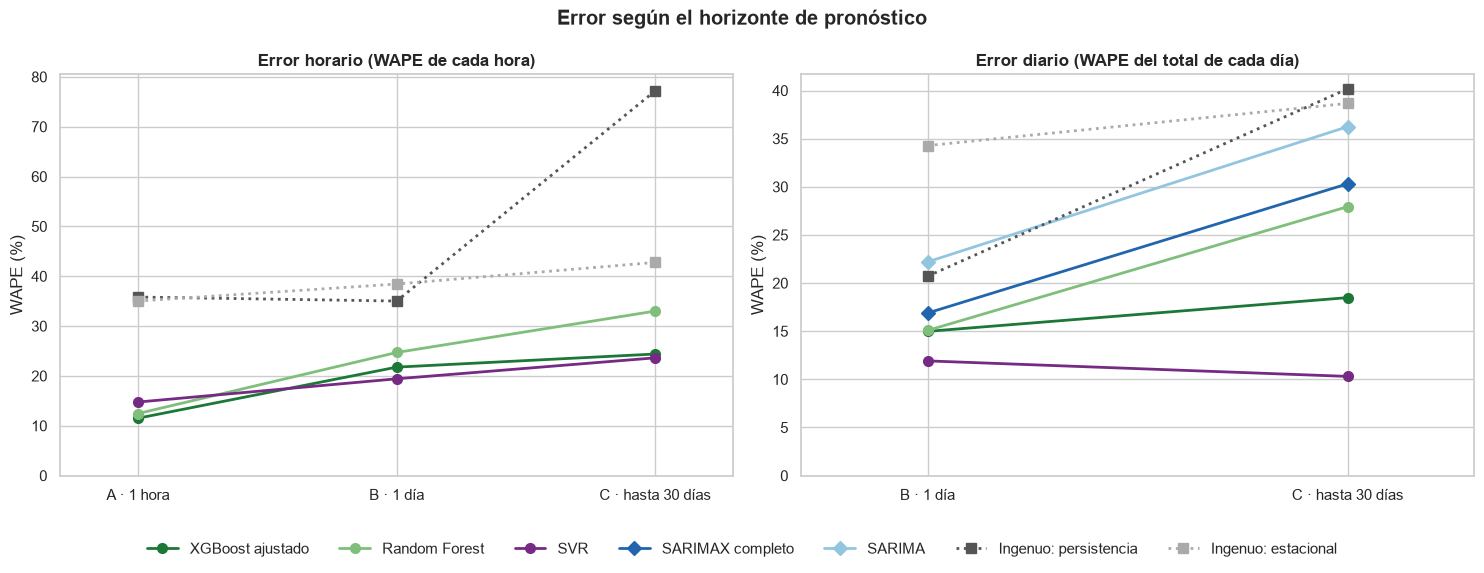

horario                                diario  \
                        A · 1 hora B · 1 día C · hasta 30 días B · 1 día   
XGBoost ajustado             11.50     21.80             24.40     15.00   
Random Forest                12.40     24.70             33.00     15.10   
XGBoost                      13.20     23.00             31.30     14.30   
SVR                          14.80     19.40             23.60     11.90   
Ridge                        24.40     28.70             41.00     20.00   
Ingenuo: estacional          35.00     38.40             42.80     34.30   
Ingenuo: persistencia        35.80     35.00             77.20     20.70   
SARIMAX completo               NaN       NaN               NaN     16.90   
SARIMAX solo clima             NaN       NaN               NaN     17.20   
SARIMAX solo calendario        NaN       NaN               NaN     20.30   
ARIMA(1, 1, 1)                 NaN       NaN               NaN     22.10   
SARIMA                         NaN       NaN               NaN     22.20   
ARIMA(2, 1, 2) auto            NaN       NaN               NaN     24.20   

                                           
                        C · hasta 30 días  
XGBoost ajustado                    18.50  
Random Forest                       27.90  
XGBoost                             25.30  
SVR                                 10.30  
Ridge                               24.80  
Ingenuo: estacional                 38.70  
Ingenuo: persistencia               40.20  
SARIMAX completo                    30.30  
SARIMAX solo clima                  30.50  
SARIMAX solo calendario             30.50  
ARIMA(1, 1, 1)                      39.10  
SARIMA                              36.30  
ARIMA(2, 1, 2) auto                 38.40

In [10]:
horario = pd.DataFrame({"A · 1 hora": {m: v["WAPE"] for m, v in r_a["metricas"].items()},
                        "B · 1 día": {m: v["WAPE"] for m, v in r_b["horario"].items()},
                        "C · hasta 30 días": {m: v["WAPE"] for m, v in r_c["horario"].items()}})
diario = pd.DataFrame({"B · 1 día": {m: v["WAPE"] for m, v in r_b["diario"].items()},
                       "C · hasta 30 días": {m: v["WAPE"] for m, v in r_c["diario"].items()}})

# Selección para la figura; la tabla de abajo tiene todos los modelos.
estilos = {
    "XGBoost ajustado": dict(color="#1b7837", marker="o"),
    "Random Forest": dict(color="#7fbf7b", marker="o"),
    "SVR": dict(color="#762a83", marker="o"),
    "SARIMAX completo": dict(color="#2166ac", marker="D"),
    "SARIMA": dict(color="#92c5de", marker="D"),
    PERSISTENCIA: dict(color="#555555", marker="s", ls=":"),
    ESTACIONAL: dict(color="#aaaaaa", marker="s", ls=":"),
}
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, df, titulo in ((ejes[0], horario, "Error horario (WAPE de cada hora)"), (ejes[1], diario, "Error diario (WAPE del total de cada día)")):
    for m, kw in estilos.items():
        if m in df.index and df.loc[m].notna().any():
            ax.plot(df.columns, df.loc[m], lw=2, ms=7, label=m, **kw)
    ax.set(title=titulo, ylabel="WAPE (%)", ylim=(0, None)); ax.set_xlim(-0.3, len(df.columns) - 0.7)
manijas, etiquetas = ejes[1].get_legend_handles_labels()
fig.legend(manijas, etiquetas, loc="lower center", ncol=len(etiquetas), frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.suptitle("Error según el horizonte de pronóstico", fontweight="bold")
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.savefig(FIGURAS / "error_por_horizonte.png", dpi=120, bbox_inches="tight"); plt.show()
pd.concat({"horario": horario, "diario": diario}, axis=1).round(1)

- **De una hora a un día**, el error horario de los modelos de ML casi se duplica (XGBoost ajustado pasa del 11,5 % al 21,8 %). Buena parte de la ventaja a una hora viene de conocer la demanda de la hora anterior, y desaparece en cuanto el pronóstico se hace la víspera.
- **De un día a un mes**, el error horario de los mejores modelos de ML apenas crece (21,8 % → 24,4 % en XGBoost ajustado); el de los modelos más débiles sí crece mucho, porque el pronóstico recursivo acumula sus propios errores.
- **En el total diario**, los SARIMAX pasan del 17 % a un día al 30 % a un mes, y SARIMA del 22 % al 36 %. Los modelos de ML conservan mejor la precisión con el horizonte porque reconstruyen el perfil de cada día con el calendario y el clima, en lugar de prolongar el nivel reciente.

## Rendimiento según el tipo de día y el periodo

### La semana de fiestas decide el orden

In [11]:
filas = {}
for esc in ("B", "C"):
    for m, g in grupos[f"prueba_{esc}_periodo"].items():
        filas[(esc, m)] = {k: v["WAPE"] for k, v in g.items()}
periodos = pd.DataFrame(filas).T
periodos.index.names = ["escenario", "modelo"]
periodos.sort_values(["escenario", "2 a 21 dic"]).round(1)

2 a 21 dic  22 a 31 dic
escenario modelo                                          
B         Random Forest                  8.80        52.80
          SVR                            9.10        28.80
          XGBoost                        9.50        42.90
          SARIMAX completo               9.90        58.80
          SARIMAX solo clima             9.90        60.40
          Ridge                          9.90        80.20
          XGBoost ajustado              10.20        43.30
          SARIMAX solo calendario       12.00        70.50
          ARIMA(1, 1, 1)                12.10        81.90
          SARIMA                        12.60        79.40
          ARIMA(2, 1, 2) auto           13.10        91.00
          Ingenuo: persistencia         15.10        54.40
          Ingenuo: estacional           17.30       136.00
C         SVR                            7.20        28.70
          XGBoost                        8.90       123.20
          SARIMAX completo              11.20       144.60
          SARIMAX solo clima            11.30       145.40
          XGBoost ajustado              11.60        59.50
          Ingenuo: persistencia         12.50       205.60
          ARIMA(1, 1, 1)                14.60       185.20
          SARIMAX solo calendario       15.00       122.80
          SARIMA                        15.60       159.50
          Ingenuo: estacional           16.90       168.60
          Random Forest                 17.20        92.10
          ARIMA(2, 1, 2) auto           17.70       162.50
          Ridge                         18.10        65.00

Del 2 al 21 de diciembre, en el escenario B, los mejores modelos quedan casi empatados: Random Forest 8,8 %, SVR 9,1 %, XGBoost 9,5 %, SARIMAX completo 9,9 %, XGBoost ajustado 10,2 %. Las diferencias de la tabla del escenario B vienen casi enteras de los diez días entre el 22 y el 31 de diciembre, cuando la demanda cae a una fracción de la habitual. En ese tramo el error se multiplica en todos los modelos, y el SVR es el que mejor sigue la caída (29 % frente a 43–59 % del resto).

Eso tiene una consecuencia práctica: con solo 30 días de prueba, y diez de ellos atípicos, el orden entre los mejores modelos **no es una base sólida para elegir uno**. La validación cruzada del notebook 03, que cubre año y medio, favorece con claridad a XGBoost, y el SVR es en ella el modelo más inestable.

### Tipo de día

In [12]:
filas = {}
for esc in ("B", "C"):
    for m, g in grupos[f"prueba_{esc}_tipo_de_dia"].items():
        for tipo, v in g.items():
            filas[(esc, m, tipo)] = v["WAPE"]
s = pd.Series(filas).unstack()
s = s[s.index.get_level_values(1).isin(INGENUOS + ["SVR", "XGBoost ajustado", "SARIMAX completo", "SARIMA"])]
s.round(1)

fin de semana o festivo  laboral
B Ingenuo: estacional                      51.30    28.50
  Ingenuo: persistencia                    31.70    17.00
  SARIMA                                   36.20    17.50
  SARIMAX completo                         37.80     9.80
  SVR                                      17.20    10.10
  XGBoost ajustado                         22.40    12.50
C Ingenuo: estacional                      54.80    33.20
  Ingenuo: persistencia                    75.80    28.10
  SARIMA                                   55.10    29.90
  SARIMAX completo                         58.20    20.90
  SVR                                      14.90     8.70
  XGBoost ajustado                         24.00    16.60

In [13]:
cv = leer("validacion_cruzada.json")
filas = []
for esc in ("A", "B"):
    m = f"{cv[esc]['mejor_base']} ajustado"
    for g in ("estacion", "tipo_de_dia"):
        t = pd.DataFrame(grupos[f"validacion_{esc}_{g}"][m]).T[["WAPE", "MAE"]]
        t.index = pd.MultiIndex.from_product([[f"{esc} · {m}"], t.index]); filas.append(t)
pd.concat(filas).round(1)

WAPE   MAE
A · XGBoost ajustado primavera               15.60 36.60
                     verano                  13.90 32.80
                     otoño                   13.40 26.00
                     invierno                16.50 24.40
                     laboral                 14.10 30.00
                     fin de semana o festivo 15.50 31.70
B · XGBoost ajustado primavera               20.50 48.20
                     verano                  17.80 41.90
                     otoño                   19.90 38.70
                     invierno                25.80 38.10
                     laboral                 18.60 39.60
                     fin de semana o festivo 23.00 47.00

En la prueba, los días no laborales son los de mayor error en todos los modelos, porque incluyen el 25 de diciembre y los fines de semana de las fiestas. En la validación, que cubre todo el año, el patrón se repite con menos intensidad: XGBoost ajustado tiene un WAPE del 15,5 % en fines de semana y festivos frente al 14,1 % en días laborales a una hora, y del 23,0 % frente al 18,6 % a un día. Los días laborales se repiten con un perfil muy estable (los viajes al trabajo); los no laborales dependen más del tiempo y de los usuarios casuales.

### Estación

La prueba solo cubre diciembre, así que el efecto de la estación se mide en la validación: el WAPE de XGBoost ajustado es mayor en invierno (16,5 % a una hora y 25,8 % a un día) que en verano (13,9 % y 17,8 %). En invierno la demanda es baja y un mismo error absoluto pesa más; además, la nieve y el frío provocan caídas bruscas que la historia reciente no anticipa.

## Conclusiones

### ¿Cuál es el mejor modelo y por qué?

Depende del horizonte, y por eso no hay un único ganador:

- **A una hora**, XGBoost ajustado (WAPE 11,5 %, un tercio del error de las referencias). Su ventaja viene de combinar la demanda de la hora anterior con el perfil horario, el tipo de día y el clima, interacciones no lineales que los árboles capturan y un modelo lineal no.
- **A un día y a un mes**, en la prueba gana el SVR (11,9 % y 10,3 % en el total diario), pero su ventaja se concentra en la semana de fiestas; antes de ella empata con Random Forest, XGBoost y SARIMAX. Con la validación cruzada como criterio de selección, el modelo recomendado es **XGBoost ajustado**: es el mejor en validación en los dos escenarios, supera a las referencias en los tres horizontes y su error es estable entre épocas del año.

### ¿Cuándo conviene un modelo estadístico y cuándo uno de machine learning?

- **Estadístico (SARIMAX)** cuando se pronostica el total diario a pocos días, se necesitan coeficientes interpretables (cuántos alquileres resta la lluvia o suma un grado de temperatura) e intervalos de predicción, o hay pocos datos. A un día, y fuera de las fiestas, el SARIMAX queda prácticamente empatado con los mejores modelos de ML (9,9 % frente a 8,8–10,2 %), con un modelo mucho más simple. Sin exógenas, en cambio, ARIMA y SARIMA no superan a la persistencia: su valor está en combinarse con el clima.
- **Machine learning** cuando se necesita granularidad horaria (operación de estaciones y redistribución de bicicletas), cuando hay datos recientes de alta frecuencia que aprovechar (escenario A) o cuando el horizonte es largo y el perfil de cada día depende de interacciones entre hora, tipo de día y clima.

### Limitaciones

- **Clima conocido de antemano.** Todos los escenarios usan el clima real de los días pronosticados; en la práctica habría que usar un pronóstico del tiempo, con su propio error, y los errores aquí son una cota optimista.
- **Prueba corta y atípica.** 30 días de diciembre, con la semana de fiestas incluida: el orden entre los mejores modelos no es estable y depende de diez días.
- **Fiestas poco representadas.** El entrenamiento contiene una sola Navidad completa (la de 2011) y ninguna variable describe el periodo entre Navidad y Año Nuevo; los modelos solo lo ven a través de `holiday` (un día) y de la caída de la demanda reciente.
- **Parámetros fijos.** Los modelos no se reentrenan durante la prueba; los estadísticos actualizan su estado, pero no sus coeficientes.

### Dos mejoras concretas

1. **Variables de temporada festiva.** Agregar indicadoras de la semana de Acción de Gracias y del periodo del 22 de diciembre al 1 de enero, y la distancia en días al festivo más cercano, tanto a los modelos de ML como a las exógenas de SARIMAX. Es donde se concentra el error de todos los modelos.
2. **Evaluación con origen móvil.** Repetir los escenarios B y C con orígenes de pronóstico a lo largo de todo 2012 (por ejemplo, cada semana, reentrenando con la historia disponible), en lugar de un único bloque de 30 días. Así la comparación entre modelos no dependería de un mes concreto y se podría medir la variación del error entre estaciones también en la prueba.